**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 9**
Regresión Logística

---

*   NOMBRE: Nadia Crystel Molina Armendáriz
*   MATRÍCULA: 792807
---


*   NOMBRE: Rosario Aracely Merlo Yujra
*   MATRÍCULA: A01797973
---


*   NOMBRE: Jacinto Manuel Molina Peralta
*   MATRÍCULA: A01841486
---


*   NOMBRE: Manuel Mojica Ponce de León
*   MATRÍCULA: A01841365

En esta actividad trabajarás con el archivo `breast_cancer.csv`, basado en un conjunto de datos sobre características de tumores mamarios, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar si un tumor es maligno (M) o benigno (B) a partir de medidas extraídas de imágenes de biopsias. Las variables incluidas describen propiedades morfológicas y de textura del tumor y se presentan en tres tipos de medida para cada característica:

* `_mean`: valor promedio de la característica en el tumor
* `_se`: error estándar de la característica (variabilidad de la medición)
* `_worst`: peor valor observado de la característica en el tumor

Los indicadores incluidos son:
* `radius_mean` / `radius_se` / `radius_worst`:	Radio del tumor
* `texture_mean` / `texture_se` / `texture_worst`:	Textura del tumor (desviación estándar de intensidad)
* `perimeter_mean` / `perimeter_se` / `perimeter_worst`:	Perímetro del tumor
* `area_mean` / `area_se` / `area_worst`:	Área del tumor
* `smoothness_mean` / `smoothness_se` / `smoothness_worst`:	Suavidad (irregularidad del borde)
* `compactness_mean` / `compactness_se` / `compactness_worst`:	Compacidad (perimeter^2 / area - 1)
* `concavity_mean` / `concavity_se` / `concavity_worst`:	Concavidad de los contornos
* `concave points_mean` / `concave points_se` / `concave points_worst`:	Número de puntos cóncavos en el contorno
* `symmetry_mean` / `symmetry_se` / `symmetry_worst`:	Simetría del tumor
* `fractal_dimension_mean` / `fractal_dimension_se` / `fractal_dimension_worst`:	Dimensión fractal del contorno (complejidad)
* `diagnosis`: Indica si el tumor es benigno (B) o maligno (M). Es la variable de salida o *target*

In [ ]:
# Importar las bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. Descarga el archivo: `breast_cancer.csv` y guarda, en un dataframe (`cancer_df`), todos sus registros.
* Haz que la columna `id` sea el nuevo índice.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.
* Obtén las estadísticas descriptivas, separando las variables numéricas (con asimetría y curtosis) y las categóricas.

In [ ]:
# Descarga el archivo: breast_cancer.csv y guarda, en un dataframe (cancer_df), todos sus registros.
cancer_df = pd.read_csv('/content/drive/MyDrive/breast_cancer.csv')
cancer_df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
# Haz que la columna id sea el nuevo índice.
cancer_df.set_index('id',inplace=True)
cancer_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820


In [ ]:
# Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

Del dataframe 30 columnas son numéricas y 1 de texto.

In [ ]:
# Verifica si alguna columna contiene valores faltantes.
cancer_df.isna().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


Ninguna columna tiene valores faltantes.

In [ ]:
# Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.
duplicados = cancer_df.duplicated().sum()
print(f"Registros duplicados: {duplicados}")
if duplicados > 0:
    cancer_df.drop_duplicates(inplace=True)
    cancer_df.reset_index(drop=True, inplace=True)

Registros duplicados: 0


No existen registros duplicados.

In [ ]:
#Estadísticas descriptivas de variables numéricas con Asimetría y Curtosis
num_cols = cancer_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = cancer_df.select_dtypes(exclude=np.number).columns.tolist()
desc_num = cancer_df[num_cols].describe().T
desc_num['skewness'] = cancer_df[num_cols].skew()
desc_num['kurtosis'] = cancer_df[num_cols].kurt()

In [ ]:
print("Estadísticas Descriptivas Numéricas")
display(desc_num[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']].round(3))

In [ ]:
#Estadísticas descriptivas y frecuencias de la variable categórica
print("Estadísticas de Variables Categóricas")
display(cancer_df[cat_cols].describe())
print("Frecuencias de 'diagnosis':")
print(cancer_df['diagnosis'].value_counts())

Estadísticas de Variables Categóricas


,diagnosis
count,569
unique,2
top,B
freq,357


Frecuencias de 'diagnosis':
diagnosis
B    357
M    212
Name: count, dtype: int64


El conjunto de datos contiene 569 observaciones y 31 columnas una vez que id se asignó como índice. Se identifican 30 variables numéricas continuas (float64), que representan medidas morfológicas y de textura divididas en tres sufijos (_mean, _se y _worst), y 1 variable de texto / categórica (diagnosis, tipo object), que constituye la variable objetivo.

No se registran valores nulos (0 faltantes en todas las columnas) ni registros duplicados (0), por lo que no se requirió imputación ni eliminación de filas.

La gran mayoría de los predictores numéricos presentan asimetría positiva (skewness > 0) y curtosis positiva (leptocúrtica), especialmente en variables de área (area_mean, area_se), dimensión fractal y puntos cóncavos, reflejando distribuciones con colas extendidas a la derecha. La variable objetivo diagnosis presenta 357 casos benignos (B) y 212 malignos (M).

2. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Calcula y visualiza la distribución porcentual de la variable `diagnosis` usando un gráfico de barras, mostrando el porcentaje encima de cada barra. ¿Por qué la distribución de la salida es relevante en un problema de clasificación?
* Genera un pairplot de las variables físicas del conjunto _mean (`radius_mean`, `perimeter_mean`, `area_mean`, `texture_mean`) coloreando por la variable `diagnosis`. ¿Qué relaciones observas entre las variables físicas? ¿Qué diferencias hay entre los tumores benignos y malignos?
* Crea histogramas apilados de las variables morfológicas (`smoothness_mean`, `compactness_mean`, `concavity_mean`, `concave points_mean`, `symmetry_mean`, `fractal_dimension_mean`) coloreando por `diagnosis` para explorar la distribución de cada variable según el tipo de tumor. ¿Alguna variable parece ser un buen discriminador entre las clases?

In [ ]:
# Calcula y visualiza la distribución porcentual de la variable diagnosis usando un gráfico de barras, mostrando el porcentaje encima de cada barra.
porcentajes = cancer_df['diagnosis'].value_counts(normalize=True) * 100
porcentajes

,proportion
diagnosis,
B,62.741652
M,37.258348


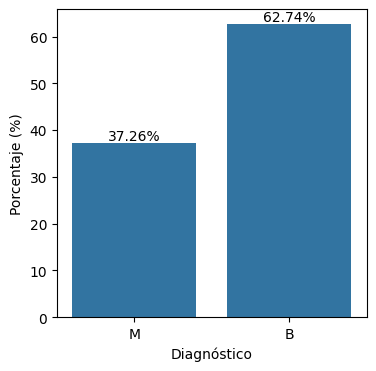

In [ ]:
plt.figure(figsize=(4,4))
ax = sns.countplot(data=cancer_df, x='diagnosis',stat='percent')
ax.bar_label(ax.containers[0], fmt='%.2f%%')

plt.xlabel('Diagnóstico')
plt.ylabel('Porcentaje (%)')
plt.show()


**¿Por qué la distribución de la salida es relevante en un problema de clasificación?**
La distribución de salida resulta relevante ya que esto nos permite identificar algún desbalance en las categorías, si esto sucediera el modelo podría favorecer la predicción de una categoría sobre otra.

La clase benigna representa el 62.7% (357) y la maligna el 37.3% (212). Conocer esta distribución es vital porque un desbalance severo podría hacer que métricas como la exactitud (accuracy) sean engañosas (un clasificador trivial prediciendo solo 'B' tendría  aprox.63% de acierto sin detectar ningún tumor canceroso). Aunque existe desbalance moderado, ambas clases cuentan con suficiente representación para entrenar el modelo.

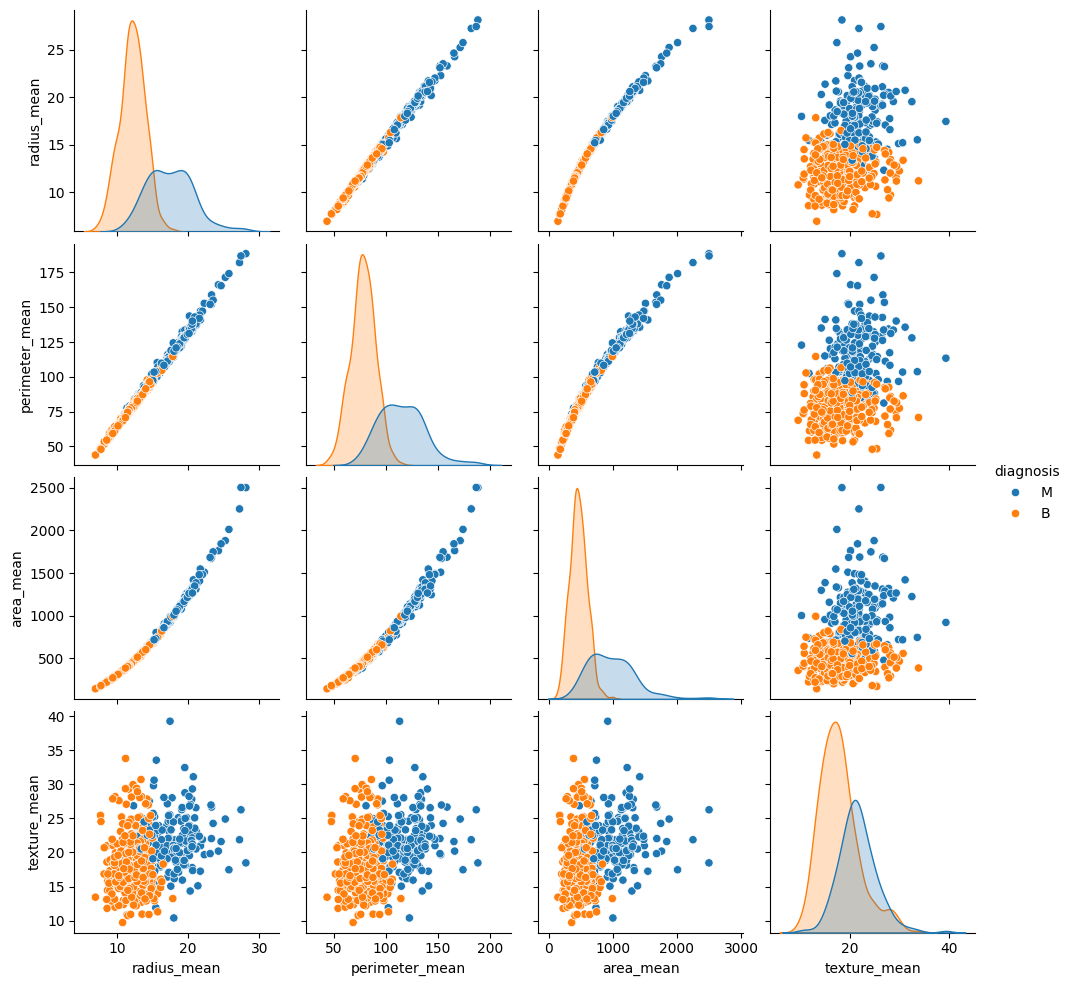

In [ ]:
# Genera un pairplot de las variables físicas del conjunto _mean (radius_mean, perimeter_mean, area_mean, texture_mean) coloreando por la variable diagnosis.
sns.pairplot(cancer_df,vars=['radius_mean', 'perimeter_mean', 'area_mean', 'texture_mean'],hue='diagnosis')

**¿Qué relaciones observas entre las variables físicas?**
Existe una relación positiva muy fuerte entre área, perímetro y radio.
Conforme aumenta el radio, también aumentan el perímetro y el área del tumor.

**¿Qué diferencias hay entre los tumores benignos y malignos?**
Los tumores benignos cuentan principalmente con valores menores de área, perímetro y radio mientras que los malignos cuentan generalmente con valores mayores.
En el caso de la textura existe superposición entre ambas categorías, sin embargo, los malignos tienden a presentar valores más altos.

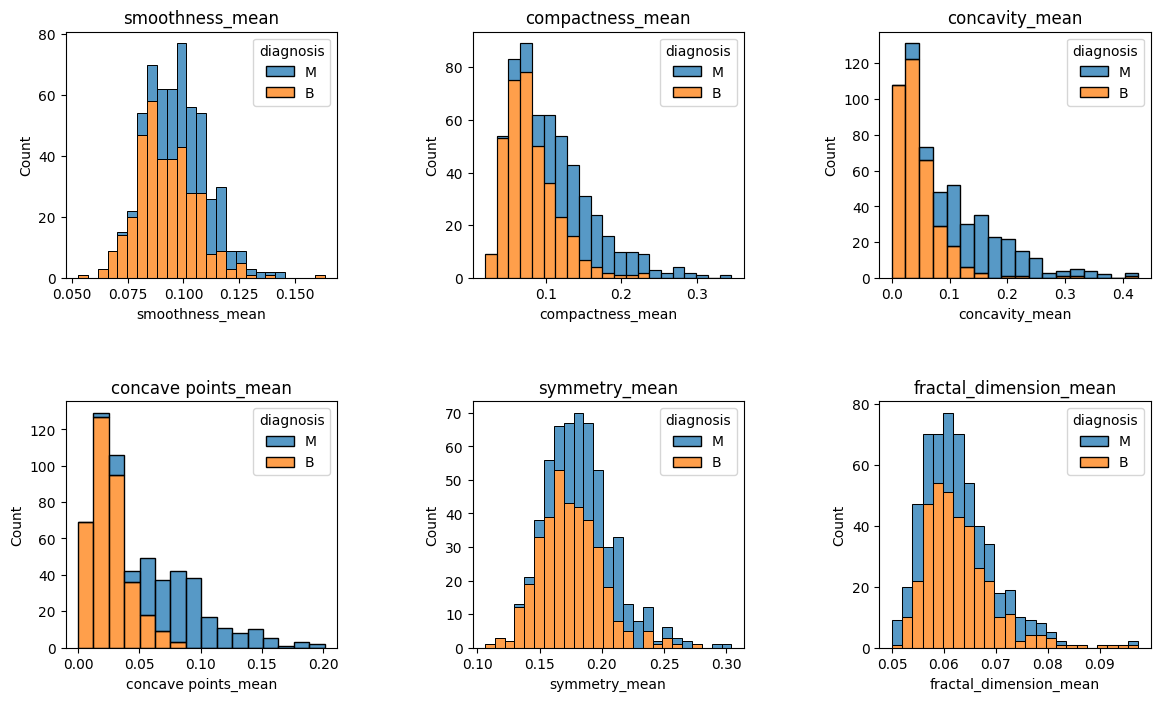

In [ ]:
# Crea histogramas apilados de las variables morfológicas (smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean)
# coloreando por diagnosis para explorar la distribución de cada variable según el tipo de tumor.
varmorf = ['smoothness_mean', 'compactness_mean','concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
plt.subplots_adjust(hspace=0.5, wspace=0.5)
axes = axes.ravel()

for variable, ax in zip(varmorf, axes):
    sns.histplot(data=cancer_df, x=variable, hue='diagnosis', multiple='stack', ax=ax)
    ax.set_title(variable)

**¿Alguna variable parece ser un buen discriminador entre las clases?**

Compactness_mean, concavity_mean y concave points_mean parecen ser las que mejor permiten distinguir entre los tumores benignos y malignos. Los tumores benignos se concentran en valores bajos mientras que los malignos presentan valores mayores.

Para el resto de las variables existe mayor superposición entre ambas categorías, esto dificulta diferenciarlas de manera visual.

3. Antes de realizar el análisis de correlación, crea una copia del dataframe (`cancer_copy`).
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos. La alta correlación entre las variables del conjunto _mean y _worst es inevitable, ya que las columnas _worst representan esencialmente los valores máximos de las mismas características medidas en _mean. Elimina las columnas _worst para simplificar el análisis.
* Imprime nuevamente los pares con correlación superior a 0.9. Como habías observado previamente, existen relaciones lineales entre `radius`, `perimeter` y `area`, por lo que era esperable encontrar altas correlaciones. De estas tres medidas, ¿cuál mantendrías y por qué? Elimina todas las variables de los otros dos conjuntos.
* Dibuja un mapa de calor con la matriz de correlación para identificar si prevalece alguna correlación relevante. Si eliminas alguna otra variable, justifica tu elección.

In [ ]:
# Antes de realizar el análisis de correlación, crea una copia del dataframe (cancer_copy).
cancer_copy = cancer_df.copy()

In [ ]:
# Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos. La alta correlación entre las variables del conjunto _mean y _worst es inevitable,
# ya que las columnas _worst representan esencialmente los valores máximos de las mismas características medidas en _mean. Elimina las columnas _worst para simplificar el análisis.
corr = cancer_copy.select_dtypes(include='number').corr().abs()
pares = corr.unstack()
pares = pares[(pares > 0.9) & (pares < 1)]
pares = pares.sort_values(ascending=False)
print(pares.iloc[::2])

radius_mean          perimeter_mean          0.997855
radius_worst         perimeter_worst         0.993708
radius_mean          area_mean               0.987357
area_mean            perimeter_mean          0.986507
area_worst           radius_worst            0.984015
                     perimeter_worst         0.977578
perimeter_se         radius_se               0.972794
perimeter_worst      perimeter_mean          0.970387
radius_mean          radius_worst            0.969539
radius_worst         perimeter_mean          0.969476
radius_mean          perimeter_worst         0.965137
radius_worst         area_mean               0.962746
area_worst           area_mean               0.959213
area_mean            perimeter_worst         0.959120
radius_se            area_se                 0.951830
area_worst           perimeter_mean          0.941550
                     radius_mean             0.941082
area_se              perimeter_se            0.937655
concave points_mean  concavi

In [ ]:
cancer_copy = cancer_copy.drop(columns=[col for col in cancer_copy.columns if col.endswith('_worst')])

In [ ]:
# Imprime nuevamente los pares con correlación superior a 0.9. Como habías observado previamente, existen relaciones lineales entre radius, perimeter y area,
# por lo que era esperable encontrar altas correlaciones.
corr = cancer_copy.select_dtypes(include='number').corr().abs()
pares = corr.unstack()
pares = pares[(pares > 0.9) & (pares < 1)]
pares = pares.sort_values(ascending=False)
print(pares.iloc[::2])

radius_mean     perimeter_mean         0.997855
                area_mean              0.987357
perimeter_mean  area_mean              0.986507
radius_se       perimeter_se           0.972794
area_se         radius_se              0.951830
perimeter_se    area_se                0.937655
concavity_mean  concave points_mean    0.921391
dtype: float64


**De estas tres medidas, ¿cuál mantendrías y por qué?**

Las tres describen el tamaño del tumor y comparten casi la misma información (correlaciones > 0.98). Mantendría el **radio** porque es la medida base: el perímetro (≈ 2πr) y el área (≈ πr²) se derivan de él. Además, el radio presenta menor asimetría (0.94) que el área (1.65), por lo que conserva la información de tamaño con menos sesgo. Por ello se eliminan todas las variables de `perimeter_` y `area_`.

In [ ]:
# Elimina todas las variables de los otros dos conjuntos.
cancer_copy = cancer_copy.drop(columns=[col for col in cancer_copy.columns if col.startswith(('perimeter_','area_'))])

<Axes: >

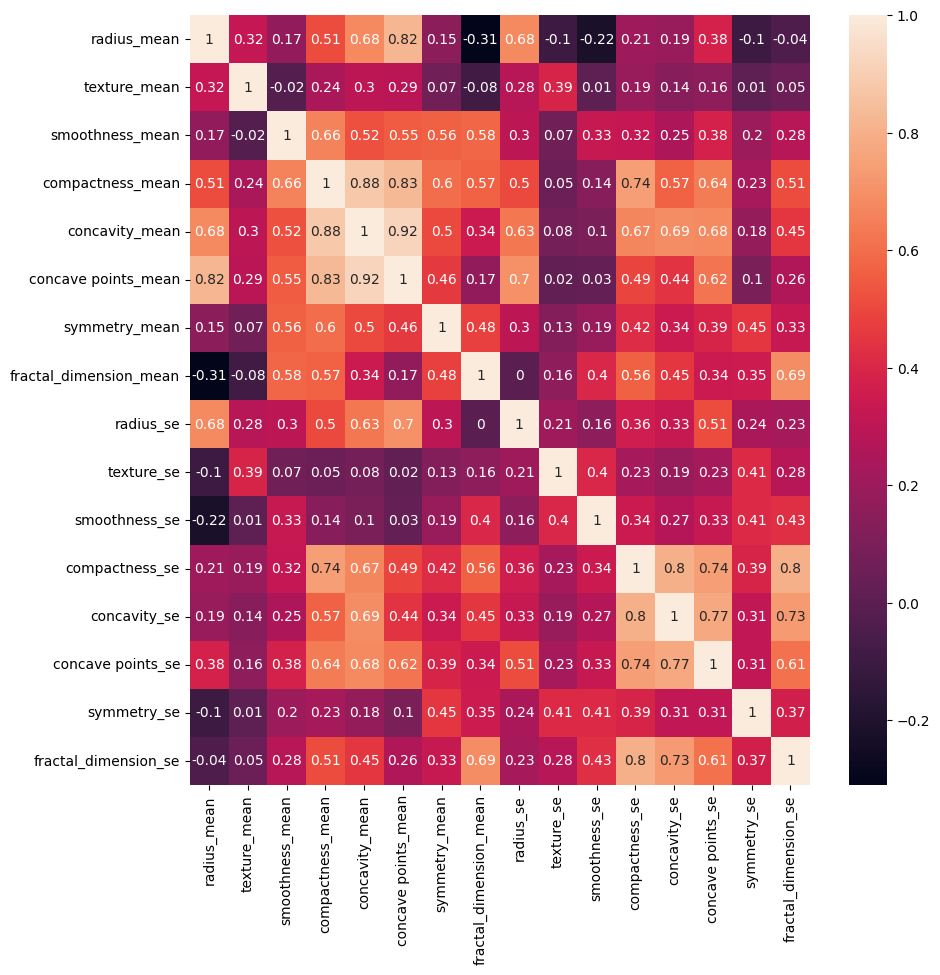

In [ ]:
# Dibuja un mapa de calor con la matriz de correlación para identificar si prevalece alguna correlación relevante. Si eliminas alguna otra variable, justifica tu elección.
plt.figure(figsize=(10,10))
sns.heatmap(round(cancer_copy.corr(numeric_only=True),2),annot=True)

Existe una correlación relevante para concavity_mean y concave points_mean (0.92), el resto son menores a 0.90, se decidió eliminar concavity_mean para reducir la redundancia en el conjunto de datos.

In [ ]:
cancer_copy.drop(columns=['concavity_mean'], inplace=True)

<Axes: >

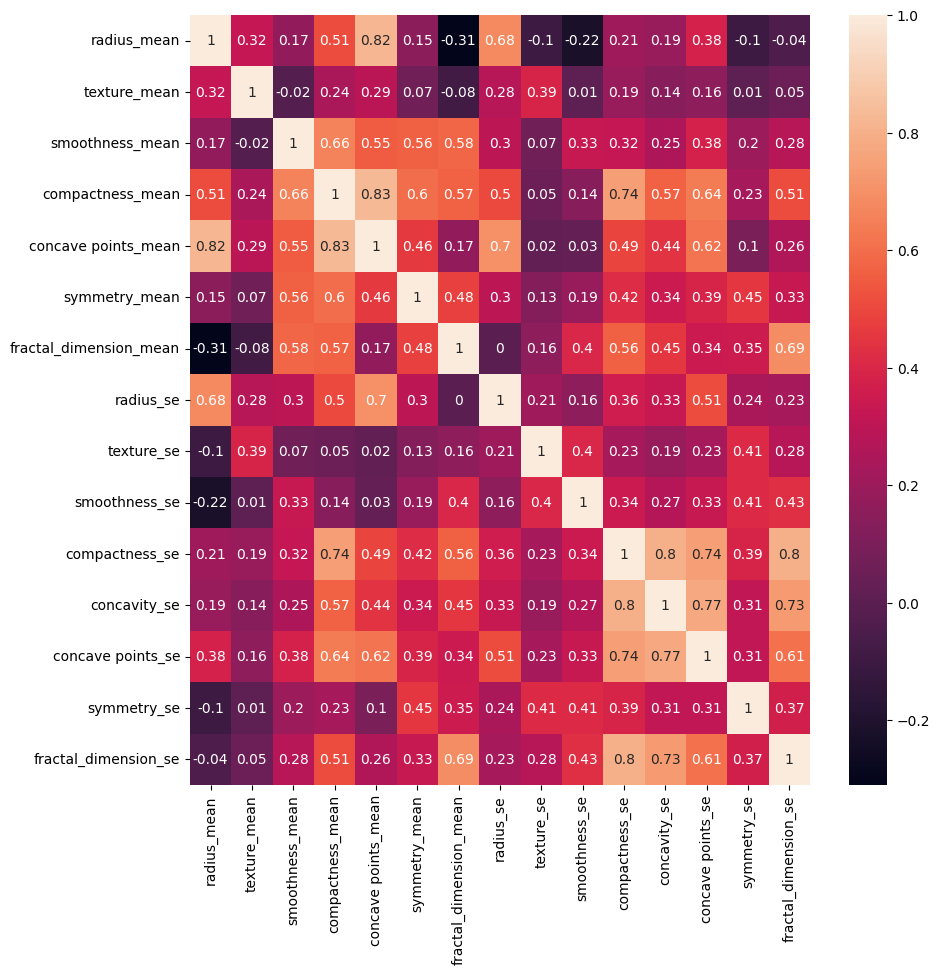

In [ ]:
plt.figure(figsize=(10,10))
sns.heatmap(round(cancer_copy.corr(numeric_only=True),2),annot=True)

4. Separa las variables predictoras `X` de la variable de salida `y`, usando el dataframe original `cancer_df` (la eliminación de variables correlacionadas se integrará en el pipeline).
* Codifica `diagnosis` como 0 (Benigno) y 1 (Maligno).
* Divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Para evaluar los modelos que se construirán, define una función llamada `evaluate_model` que reciba los valores reales y las predicciones e imprima las métricas de recall, precisión y exactitud (accuracy).

In [ ]:
# 1. Separar predictores X y variable objetivo y desde el dataframe original
X = cancer_df.drop(columns=['diagnosis'])
y = cancer_df['diagnosis'].map({'B': 0, 'M': 1})

In [ ]:
# 2. Partición entrenamiento y prueba (80:20) con random_state=1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=1, stratify=None
)

In [ ]:
print(f"Dimensiones de X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Dimensiones de X_test:  {X_test.shape} | y_test:  {y_test.shape}")

Dimensiones de X_train: (455, 30) | y_train: (455,)
Dimensiones de X_test:  (114, 30) | y_test:  (114,)


In [ ]:
# 3. Definición de la función de evaluación
def evaluate_model(y_true, y_pred, model_name="Modelo"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)

    print(f"=== Métricas de Desempeño: {model_name} ===")
    print(f"Exactitud (Accuracy): {acc:.4f}")
    print(f"Precisión (Precision): {prec:.4f}")
    print(f"Exhaustividad (Recall): {rec:.4f}\n")

    return {'Modelo': model_name, 'Exactitud': acc, 'Precision': prec, 'Recall': rec}

5. Prepara un transformador denominado `preprocessing`, usando ColumnTransformer, para borrar las columnas altamente correlacionadas (identificadas en el ejercicio 3) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.
* Crea un pipeline que integre el transformador y regresión logística para  entrenar un modelo.
* Evalúa el desempeño del modelo en el conjunto de prueba empleando la función `evaluate_model`.
* Integra los resultados en un dataframe que contenga el nombre del modelo (*Correlation_Clean*) y una columna para cada métrica calculada.

In [ ]:
# 1. Lista de variables a eliminar identificadas en el Ejercicio 3 (15 columnas en total)
cols_a_eliminar = [c for c in X.columns if c.endswith('_worst')] + \
                  [c for c in X.columns if c.startswith(('perimeter_', 'area_'))] + \
                  ['concavity_mean']

In [ ]:
# 2. Configurar ColumnTransformer con remainder='passthrough'
preprocessing = ColumnTransformer(
    transformers=[
        ('drop_redundantes', 'drop', cols_a_eliminar)
    ],
    remainder='passthrough'
)

In [ ]:
# 3. Construcción del Pipeline
pipeline_clean = Pipeline([
    ('preprocessing', preprocessing),
    ('classifier', LogisticRegression(max_iter=1000, random_state=1))
])

In [ ]:
# 4. Entrenamiento y Evaluación
pipeline_clean.fit(X_train, y_train)
y_pred_clean = pipeline_clean.predict(X_test)

In [ ]:
res_clean = evaluate_model(y_test, y_pred_clean, model_name="Correlation_Clean")
resultados_df = pd.DataFrame([res_clean])
display(resultados_df)

Se implementó un pipeline que utiliza ColumnTransformer para descartar las 15 columnas redundantes y retiene las 15 variables no colineales mediante remainder='passthrough'. El modelo alcanza una Exactitud del 87.72%, Precisión del 88.89% y un Recall del 76.19%.
El desempeño se ve restringido porque los predictores no han sido escalados, lo que dificulta la convergencia óptima de los coeficientes de regresión logística.

6. Una alternativa para reducir la multicolinealidad es el análisis de componentes principales. Construye un pipeline que incluya escalado estándar, PCA y regresión logística, manteniendo el número mínimo de componentes principales que expliquen al menos el 90% de la varianza.
* Entrena el modelo utilizando el conjunto de entrenamiento y evalúalo en el conjunto de prueba.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Standard_PCA*.
* ¿Cuántos componentes principales se emplearon?

In [ ]:
# 1. Pipeline con StandardScaler, PCA (mínimo 90% varianza) y LogisticRegression
pipeline_pca = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.90, random_state=1)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=1))
])

In [ ]:
# 2. Entrenamiento y Evaluación
pipeline_pca.fit(X_train, y_train)
y_pred_pca = pipeline_pca.predict(X_test)

In [ ]:
# Extraer el número de componentes utilizados
pca_fitted = pipeline_pca.named_steps['pca']
n_comp = pca_fitted.n_components_
var_acum = pca_fitted.explained_variance_ratio_.sum() * 100

print(f"Componentes principales empleados: {n_comp}")
print(f"Varianza total explicada acumulada: {var_acum:.2f}%\n")

Componentes principales empleados: 7
Varianza total explicada acumulada: 91.08%



In [ ]:
# 3. Registrar resultados
res_pca = evaluate_model(y_test, y_pred_pca, model_name="Standard_PCA")
resultados_df = pd.concat([resultados_df, pd.DataFrame([res_pca])], ignore_index=True)
display(resultados_df)

=== Métricas de Desempeño: Standard_PCA ===
Exactitud (Accuracy): 0.9737
Precisión (Precision): 1.0000
Exhaustividad (Recall): 0.9286



,Modelo,Exactitud,Precision,Recall
0,Correlation_Clean,0.877193,0.888889,0.761905
1,Standard_PCA,0.973684,1.000000,0.928571


Se utilizaron 7 componentes principales para superar el umbral del 90% de la varianza total de los datos originales (91.08% de variabilidad capturada).

Al escalar las variables y proyectarlas en un espacio ortogonal sin multicolinealidad, el modelo incrementa sustancialmente su rendimiento frente al modelo base: la Exactitud se eleva al 97.37%, la Precisión alcanza el 100.0% y el Recall sube al 92.86%

7. Como intento de mejorar las métricas del modelo, y dado que todas las variables presentan sesgo, aplica una normalización utilizando Yeo-Johnson. Para ello:
* Crea un pipeline que integre el transformador `preprocessing`, una transformación Yeo-Johnson y regresión logística.
* Entrena el modelo utilizando el conjunto de entrenamiento y evalúalo en el conjunto de prueba.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Correlation_Yeo*.

In [ ]:
# 1. Pipeline con preprocessing, PowerTransformer(Yeo-Johnson) y LogisticRegression
pipeline_yeo = Pipeline([
    ('preprocessing', preprocessing),
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('classifier', LogisticRegression(max_iter=1000, random_state=1))
])

In [ ]:
# 2. Entrenamiento y Evaluación
pipeline_yeo.fit(X_train, y_train)
y_pred_yeo = pipeline_yeo.predict(X_test)

In [ ]:
# 3. Registrar resultados
res_yeo = evaluate_model(y_test, y_pred_yeo, model_name="Correlation_Yeo")
resultados_df = pd.concat([resultados_df, pd.DataFrame([res_yeo])], ignore_index=True)
display(resultados_df)

=== Métricas de Desempeño: Correlation_Yeo ===
Exactitud (Accuracy): 0.9825
Precisión (Precision): 1.0000
Exhaustividad (Recall): 0.9524



,Modelo,Exactitud,Precision,Recall
0,Correlation_Clean,0.877193,0.888889,0.761905
1,Standard_PCA,0.973684,1.000000,0.928571
2,Correlation_Yeo,0.982456,1.000000,0.952381


La normalización de potencia Yeo-Johnson corrige el sesgo y asimetría positiva diagnosticados en la Pregunta 1, estabilizando la varianza y aproximando los 15 predictores limpios a distribuciones normales. El modelo Correlation_Yeo alcanza el desempeño más alto: Exactitud = 98.25%, Precisión = 100.0% y Recall = 95.24%.

8. Del modelo anterior, obtén los nombres de los predictores empleados. ¿Cuántos son?
* Revisa los coeficientes del modelo de regresión logística y analiza su magnitud para identificar las variables 10 más influyentes.
* Grafícalas en un barplot horizontal, mostrando el valor del coeficiente y respetando su signo.

In [ ]:
# 1. Extraer los nombres exactos de los predictores desde el paso de preprocesamiento
feature_names = pipeline_yeo.named_steps['preprocessing'].get_feature_names_out()
# Limpiar el prefijo 'remainder__' que scikit-learn añade a las columnas que pasaron
feature_names = [f.replace('remainder__', '') for f in feature_names]


In [ ]:
# 2. Extraer los coeficientes aplanados (1D)
coeficientes = pipeline_yeo.named_steps['classifier'].coef_[0]

In [ ]:
print(f"Total de predictores: {len(feature_names)}")
print(f"Total de coeficientes: {len(coeficientes)}")

Total de predictores: 15
Total de coeficientes: 15


In [ ]:
# 3. Crear el DataFrame sin conflictos de dimensión
coef_df = pd.DataFrame({
    'Predictor': feature_names,
    'Coeficiente': coeficientes,
    'Magnitud_Absoluta': np.abs(coeficientes)
}).sort_values(by='Magnitud_Absoluta', ascending=False)

In [ ]:
# Mostrar la tabla completa ordenada por importancia
display(coef_df)

,Predictor,Coeficiente,Magnitud_Absoluta
4,concave points_mean,2.467117,2.467117
1,texture_mean,1.906850,1.906850
0,radius_mean,1.379170,1.379170
7,radius_se,1.320211,1.320211
11,concavity_se,1.012023,1.012023
5,symmetry_mean,0.783896,0.783896
13,symmetry_se,-0.720241,0.720241
10,compactness_se,-0.697009,0.697009
3,compactness_mean,0.624829,0.624829
12,concave points_se,-0.562104,0.562104


In [ ]:
# 4. Seleccionar el Top 10 para graficar
top10_coef = coef_df.head(10).sort_values(by='Coeficiente', ascending=True)

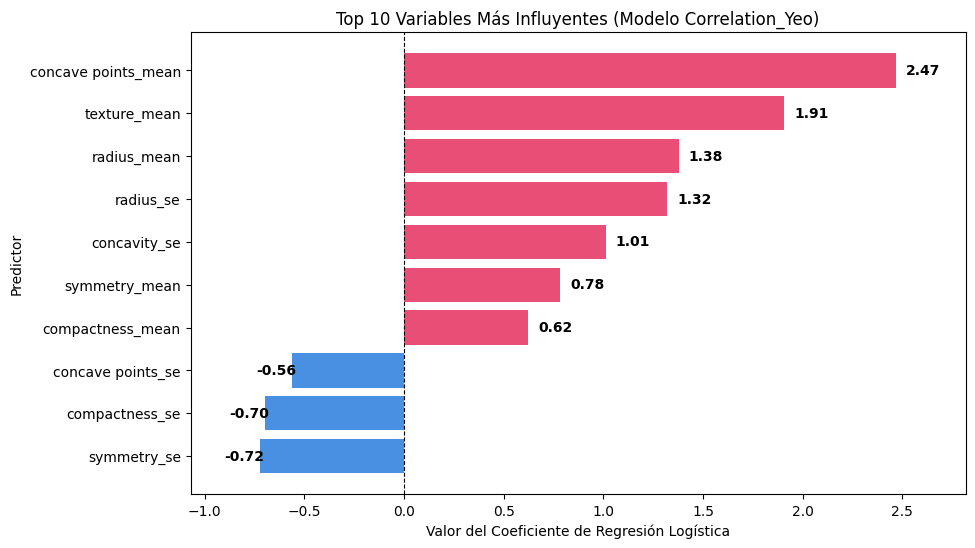

In [ ]:
# 5. Gráfico de barras horizontal respetando signos
plt.figure(figsize=(10, 6))
colores = ['#e94e77' if c > 0 else '#4a90e2' for c in top10_coef['Coeficiente']]
plt.barh(top10_coef['Predictor'], top10_coef['Coeficiente'], color=colores)

plt.title("Top 10 Variables Más Influyentes (Modelo Correlation_Yeo)")
plt.xlabel("Valor del Coeficiente de Regresión Logística")
plt.ylabel("Predictor")
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)

# Etiquetas numéricas
for i, v in enumerate(top10_coef['Coeficiente']):
    offset = 0.05 if v >= 0 else -0.18
    plt.text(v + offset, i, f"{v:.2f}", va='center', fontweight='bold')

plt.xlim(min(top10_coef['Coeficiente']) - 0.35, max(top10_coef['Coeficiente']) + 0.35)
plt.show()

El modelo conserva exactamente 15 variables predictoras tras remover las 15 características colineales (_worst, áreas, perímetros y concavidad).

Dirección y Magnitud Clínica:
* concave points_mean (+2.47) y texture_mean (+1.91) son las variables con mayor ponderación positiva. En la formulación de regresión logística, un coeficiente positivo elevado indica que a mayor cantidad de indentaciones en el contorno y mayor rugosidad/textura celular, se incrementan sustancialmente los momios (odds) de que el tumor sea maligno.
* radius_mean (+1.38) y radius_se (+1.32) confirman que tanto un mayor radio promedio como una alta variabilidad en el tamaño celular son fuertes señales de tejido cancerígeno.
* Los coeficientes negativos (symmetry_se −0.72, compactness_se −0.70) indican que, manteniendo constantes las demás variables, valores más altos de estas características **disminuyen** los momios de que el tumor sea maligno. Como Yeo-Johnson estandariza las variables, la magnitud de los coeficientes puede compararse directamente entre predictores.

9. Imprime el dataframe de resultados.
* Dibuja la matriz de confusión del mejor modelo. ¿Qué significa cada valor en ella?
* Dibuja la curva ROC del mismo modelo y describe lo que indica sobre su capacidad para distinguir entre clases.

In [ ]:
# 1. Tabla comparativa final de métricas
print("TABLA COMPARATIVA DE MODELOS")
display(resultados_df.sort_values(by=['Recall', 'Exactitud'], ascending=False))

TABLA COMPARATIVA DE MODELOS


,Modelo,Exactitud,Precision,Recall
2,Correlation_Yeo,0.982456,1.000000,0.952381
1,Standard_PCA,0.973684,1.000000,0.928571
0,Correlation_Clean,0.877193,0.888889,0.761905


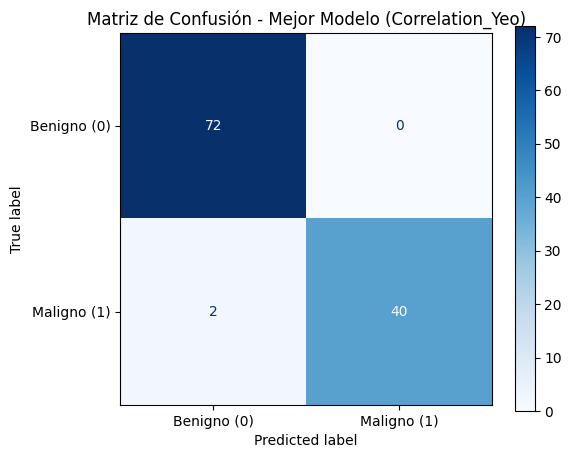

In [ ]:
# 2. Matriz de Confusión del mejor modelo (Correlation_Yeo)
cm = confusion_matrix(y_test, y_pred_yeo)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benigno (0)', 'Maligno (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Matriz de Confusión - Mejor Modelo (Correlation_Yeo)")
plt.grid(False)
plt.show()


Significado de los cuadrantes en la Matriz de Confusión:
* Verdaderos Negativos (TN = 72): Pacientes sanas (tumores benignos) clasificadas correctamente como benignas.
* Falsos Positivos (FP = 0): Ninguna paciente benigna fue clasificada erróneamente como maligna (cero falsas alarmas).
* Falsos Negativos (FN = 2): Únicamente 2 pacientes con cáncer maligno no fueron detectadas por el modelo bajo el umbral actual.
* Verdaderos Positivos (TP = 40): 40 de las 42 pacientes con cáncer maligno fueron identificadas exitosamente.

In [ ]:
# 3. Curva ROC y cálculo del AUC
y_prob_yeo = pipeline_yeo.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob_yeo)
auc_val = roc_auc_score(y_test, y_prob_yeo)


In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#e94e77', linewidth=2.5, label=f"Curva ROC (AUC = {auc_val:.4f})")
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label="Clasificador aleatorio (AUC = 0.5)")
plt.title("Curva ROC (Receiver Operating Characteristic)")
plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
plt.ylabel("Tasa de Verdaderos Positivos (Recall / Sensibilidad)")
plt.legend(loc='lower right')
plt.show()

Capacidad de distinción (Curva ROC y AUC):
* La curva se mantiene pegada a la esquina superior izquierda, muy por encima de la diagonal del clasificador aleatorio: el modelo alcanza una tasa de verdaderos positivos alta con muy pocos falsos positivos.
* El AUC = 0.9924 significa que, si se elige al azar un tumor maligno y uno benigno, hay un 99.24% de probabilidad de que el modelo asigne mayor probabilidad de malignidad al tumor maligno. El modelo separa las clases casi perfectamente.

10. Grafica la distribución de las probabilidades predichas de la clase positiva (Maligno, 1) usando histogramas superpuestos, diferenciando con colores las clases reales Benigno (B) y Maligno (M).
* ¿Cuál es el umbral (*threshold*) por defecto que utiliza scikit-learn para convertir probabilidades en predicciones binarias?
* En un modelo de diagnóstico médico, ¿cuál consideras que es la métrica más importante?
* ¿Cómo cambiarías (disminuir / aumentar) el *threshold*? ¿Por qué?

In [ ]:
# 1. Crear DataFrame con probabilidades predichas y clases reales
prob_df = pd.DataFrame({
    'Probabilidad_Maligno': y_prob_yeo,
    'Clase_Real': y_test.map({0: 'Benigno', 1: 'Maligno'}).values
})

In [ ]:
# 2. Histogramas superpuestos por clase real
plt.figure(figsize=(9, 5))
sns.histplot(data=prob_df, x='Probabilidad_Maligno', hue='Clase_Real',
             palette={'Benigno': '#4a90e2', 'Maligno': '#e94e77'},
             bins=20, multiple='layer', alpha=0.6, kde=True)

# Líneas de umbral: por defecto (0.50) y umbral clínico sugerido (0.10)
plt.axvline(0.50, color='black', linestyle='--', linewidth=2, label="Umbral por defecto (0.50)")
plt.axvline(0.10, color='red', linestyle=':', linewidth=2, label="Umbral clínico sugerido (0.10)")

plt.title("Distribución de Probabilidades Predichas por Clase Real")
plt.xlabel("Probabilidad Predicha P(Maligno = 1)")
plt.ylabel("Cantidad de Pacientes")
plt.legend()
plt.show()

¿Cuál es el umbral (threshold) por defecto de scikit-learn? El umbral predeterminado es 0.50. Si la probabilidad predicha $P(\text{Maligno}) \ge 0.50$, se asigna la clase 1 (Maligno); si es menor, se clasifica como 0 (Benigno).

¿Cuál es la métrica más importante en un diagnóstico médico? La métrica prioritaria es el Recall (Sensibilidad) de la clase positiva (Maligno). En patología oncológica, el costo clínico de un Falso Negativo (FN) es crítico y potencialmente irreversible: una paciente con tumor maligno a la que se le diga erróneamente que está sana no recibirá tratamiento oportuno. En contraste, un Falso Positivo (FP) solo deriva en pruebas confirmatorias complementarias (ej. biopsias adicionales).

In [ ]:
# Efecto de distintos umbrales sobre el modelo Correlation_Yeo
filas = []
for t in [0.50, 0.20, 0.10, 0.02]:
    y_pred_t = (y_prob_yeo >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    filas.append({'Umbral': t, 'FN': fn, 'FP': fp,
                  'Recall': recall_score(y_test, y_pred_t),
                  'Precision': precision_score(y_test, y_pred_t)})
display(pd.DataFrame(filas).round(4))

**¿Cómo cambiarías (disminuir / aumentar) el threshold y por qué?** Lo **disminuiría**. Al bajar el umbral, el modelo clasifica como maligno cualquier caso con sospecha moderada, lo que aumenta el Recall a costa de más Falsos Positivos. En este modelo, los 2 falsos negativos tienen probabilidades predichas muy bajas (≈0.17 y ≈0.03). Por eso bajar el umbral a 0.20 no recupera ninguno y solo agrega falsos positivos. Con 0.10 se recupera uno (Recall = 0.976, 11 FP), y para eliminar todos los falsos negativos habría que bajarlo a ≈0.02, con 19 FP. Un umbral cercano a 0.10 es un compromiso razonable: en diagnóstico médico un falso positivo solo implica pruebas confirmatorias, mientras que un falso negativo retrasa el tratamiento.

---

**Declaración de uso de IA**

*   Gemini. (2026). *(basado en Gemini Flash 3,5)*, utilizado para depuración de código. https://gemini.google.com/
*   Anthropic. (2026). *Claude (basado en Claude Opus 5.5)* [Modelo de lenguaje grande], utilizado para revisión de la libreta y depuración de código. https://claude.ai/